In [26]:
import numpy as np
import matplotlib.pylab as plt
import math
import pandas as pd
import seaborn as sns
import os
from matplotlib import rcParams
import pickle


In [27]:
path = r"C:\Users\Usuario\Desktop\Python\B1_5\Bearing1_5\VMD10"
samples = os.listdir(path)
samples = sorted(samples, key=lambda x: int(x.split('_')[0]))
OutPath = r'Dataset\B1_5'
for filename in samples:
    file_path = os.path.join(path, filename)
    
    # .pkz files are typically pickled data. 
    # Use 'rb' (read binary) mode to open them.
    with open(file_path, 'rb') as file:
        data = pickle.load(file)
        sig = data.iloc[:,1].values
        df = pd.DataFrame()
        df['sig'] = sig**2
        out = (os.path.join(OutPath,filename))
        df.to_csv(out)

        

# Fault-type clustering pipeline — XJTU-SY Bearing1_5

1. Load the records (32768 samples at 25.6 kHz, one per minute).
2. Characteristic fault frequencies (bearing kinematics).
3. **Stage layer**: DSI (Mahalanobis distance to the healthy baseline + EWMA) and FPT (3σ, consecutive trigger).
4. Demodulation band selection (kurtogram-like spectral kurtosis).
5. **Fault signature**: envelope-spectrum prominence at BPFO / BPFI / BSF / FTF harmonics and sidebands, in baseline-σ units.
6. **Fault layer**: clustering of the degraded records only (TEDA/AutoCloud online, GMM offline reference).

In [28]:
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf
from sklearn.mixture import GaussianMixture

DataPath = r'Dataset\B1_5'
fs = 25600            # XJTU-SY sampling rate [Hz]
fr = 2100 / 60        # condition 1 (Bearing1_x): 2100 rpm -> 35 Hz

# LDK UER204 geometry (Wang et al., IEEE Trans. Reliab., 2020)
n_balls, d_ball, D_pitch, alpha = 8, 7.92, 34.55, 0.0

# the .pkz files in Dataset\B1_5 were written by the cell above with df.to_csv -> read as csv
files = sorted(os.listdir(DataPath), key=lambda x: int(x.split('_')[0]))
X = np.array([pd.read_csv(os.path.join(DataPath, f), index_col=0)['sig'].values for f in files])
t = np.arange(1, len(X) + 1)          # one record per minute
print(X.shape)

(52, 32768)


## 2. Characteristic fault frequencies

| Fault | Formula |
|---|---|
| Outer race (BPFO) | (n/2)·fr·(1 − d/D·cosα) |
| Inner race (BPFI) | (n/2)·fr·(1 + d/D·cosα) |
| Ball spin (BSF) | (D/2d)·fr·(1 − (d/D·cosα)²) |
| Cage (FTF) | (1/2)·fr·(1 − d/D·cosα) |

In [29]:
def fault_orders(n, d, D, alpha=0.0):
    '''Characteristic fault frequencies as multiples (orders) of the shaft frequency.'''
    r = d / D * np.cos(np.deg2rad(alpha))
    return {'BPFO': n / 2 * (1 - r),
            'BPFI': n / 2 * (1 + r),
            'BSF': D / (2 * d) * (1 - r**2),
            'FTF': 0.5 * (1 - r)}

ORDERS = fault_orders(n_balls, d_ball, D_pitch, alpha)
pd.DataFrame({'order [x fr]': ORDERS, 'frequency [Hz]': {k: v * fr for k, v in ORDERS.items()}}).round(2)

,order [x fr],frequency [Hz]
BPFO,3.08,107.91
BPFI,4.92,172.09
BSF,2.07,72.33
FTF,0.39,13.49


## 3. Stage layer: DSI and FPT

A healthy bearing has no fault signature, so fault clustering only makes sense after degradation onset. DSI = Mahalanobis distance (Ledoit-Wolf covariance) of a feature vector [log RMS, log kurtosis, log envelope-band energies] to the healthy baseline (first `n_base` records), in baseline-σ units and EWMA-smoothed. FPT = first of 3 consecutive records with DSI > 3σ.

FPT: t = 27 min


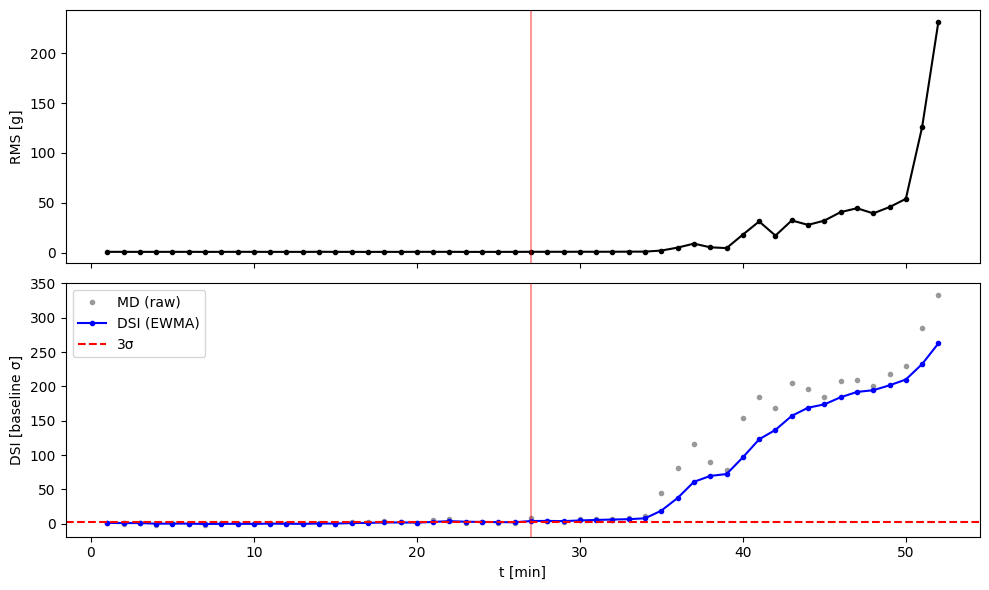

In [30]:
def envelope(x, band=None, fs=fs):
    '''Envelope via analytic signal; the band-pass is done in the frequency domain.'''
    N = len(x)
    S = np.fft.fft(x - x.mean())
    f = np.fft.fftfreq(N, 1 / fs)
    H = np.zeros(N)
    H[f > 0] = 2.0
    if band is not None:
        H[(f < band[0]) | (f > band[1])] = 0.0
    return np.abs(np.fft.ifft(S * H))

def envelope_spectrum(x, band=None, fs=fs):
    env = envelope(x, band, fs)
    env = env - env.mean()
    E = np.abs(np.fft.rfft(env * np.hanning(len(env)))) * 2 / len(env)
    return np.fft.rfftfreq(len(env), 1 / fs), E

def stage_features(x, n_bands=16, fmax=1000):
    '''log RMS, log kurtosis and log band energies of the envelope spectrum (0-fmax Hz).'''
    f, E = envelope_spectrum(x)
    edges = np.linspace(0, fmax, n_bands + 1)
    bands = [np.sum(E[(f >= a) & (f < b)]**2) for a, b in zip(edges[:-1], edges[1:])]
    rms = np.sqrt(np.mean(x**2))
    return np.r_[np.log10(rms), np.log10(kurtosis(x, fisher=False)), np.log10(np.array(bands) + 1e-12)]

def dsi_md(F, n_base=15, lam=0.3):
    '''Mahalanobis distance to the healthy baseline, in baseline-sigma units, EWMA-smoothed (causal).'''
    lw = LedoitWolf().fit(F[:n_base])
    md = np.sqrt(lw.mahalanobis(F))
    md = (md - md[:n_base].mean()) / md[:n_base].std()
    ewma = np.zeros_like(md)
    for i in range(len(md)):
        ewma[i] = lam * md[i] + (1 - lam) * (ewma[i - 1] if i else md[i])
    return md, ewma

def detect_fpt(dsi, thr=3.0, n_consec=3, start=0):
    '''First record of n_consec consecutive values above thr (avoids triggers by random noise).'''
    above = dsi > thr
    for k in range(start, len(dsi) - n_consec + 1):
        if above[k:k + n_consec].all():
            return k
    return None

n_base = 15
F_stage = np.array([stage_features(x) for x in X])
md, DSI = dsi_md(F_stage, n_base=n_base)
fpt = detect_fpt(DSI, start=n_base)
print('FPT: t =', t[fpt], 'min')

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, np.sqrt(np.mean(X**2, axis=1)), 'k.-'); ax[0].set_ylabel('RMS [g]')
ax[1].plot(t, md, '.', c='0.6', label='MD (raw)'); ax[1].plot(t, DSI, 'b.-', label='DSI (EWMA)')
ax[1].axhline(3, c='r', ls='--', label='3σ'); ax[1].set_ylabel('DSI [baseline σ]'); ax[1].set_xlabel('t [min]')
for a in ax: a.axvline(t[fpt], c='r', alpha=.4)
ax[1].legend(); fig.tight_layout(); plt.show()

## 4. Demodulation band (kurtogram-like)

Fault impacts excite a structural resonance; demodulating around it reveals the fault frequencies in the envelope spectrum. The band is chosen on a dyadic grid by maximizing the spectral kurtosis of the squared envelope over the degraded records (Antoni, 2007). Bands above 0.9·Nyquist are excluded (anti-aliasing region).

Selected band: 200-6400 Hz


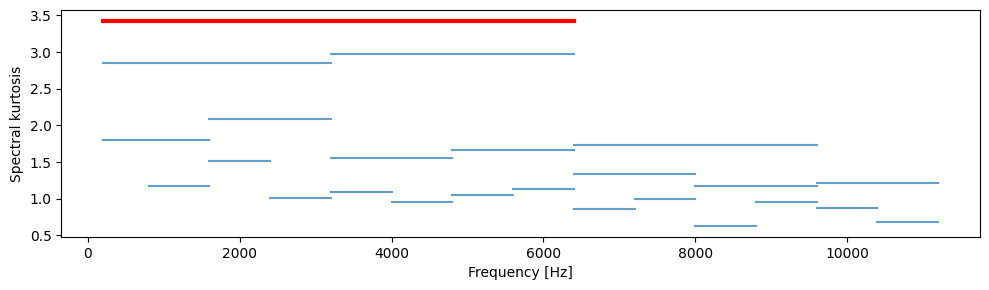

In [31]:
def band_grid(fs=fs, levels=(1, 2, 3, 4, 5, 6), fmin=200, fmax_ratio=0.9):
    '''Dyadic band grid (1/2^level of the Nyquist band), avoiding the anti-aliasing region.'''
    grid = []
    for lv in levels:
        bw = fs / 2 / 2**lv
        for i in range(2**lv):
            lo, hi = max(i * bw, fmin), (i + 1) * bw
            if hi - lo > 4 * max(ORDERS.values()) * fr and hi <= fmax_ratio * fs / 2:
                grid.append((lo, hi))
    return grid

def select_band(Xd, grid):
    '''Kurtogram criterion: band maximizing the spectral kurtosis (of the squared envelope) over degraded records.'''
    def sk(x, b):
        e2 = envelope(x, b)**2
        return np.mean(e2**2) / np.mean(e2)**2 - 2
    score = np.array([np.mean([sk(x, b) for x in Xd]) for b in grid])
    return grid[int(np.argmax(score))], score

grid = band_grid()
band, band_score = select_band(X[fpt:], grid)
print(f'Selected band: {band[0]:.0f}-{band[1]:.0f} Hz')

fig, ax = plt.subplots(figsize=(10, 3))
for (lo, hi), s in zip(grid, band_score):
    ax.plot([lo, hi], [s, s], c='tab:blue', alpha=.7)
ax.plot(band, [band_score.max()] * 2, c='r', lw=3)
ax.set_xlabel('Frequency [Hz]'); ax.set_ylabel('Spectral kurtosis'); fig.tight_layout(); plt.show()

## 5. Fault signature vector

For each characteristic order (BPFO, BPFI, BSF, FTF) and its harmonics 1–3×, plus the BPFI ±fr and 2·BSF ±FTF sidebands: the peak within ±3 % (slip) of the envelope spectrum relative to its local median (noise floor), in log10. Each feature is then z-scored with the healthy baseline (first `n_base` records), and the **fault index** of each type is the mean z-score of its features.

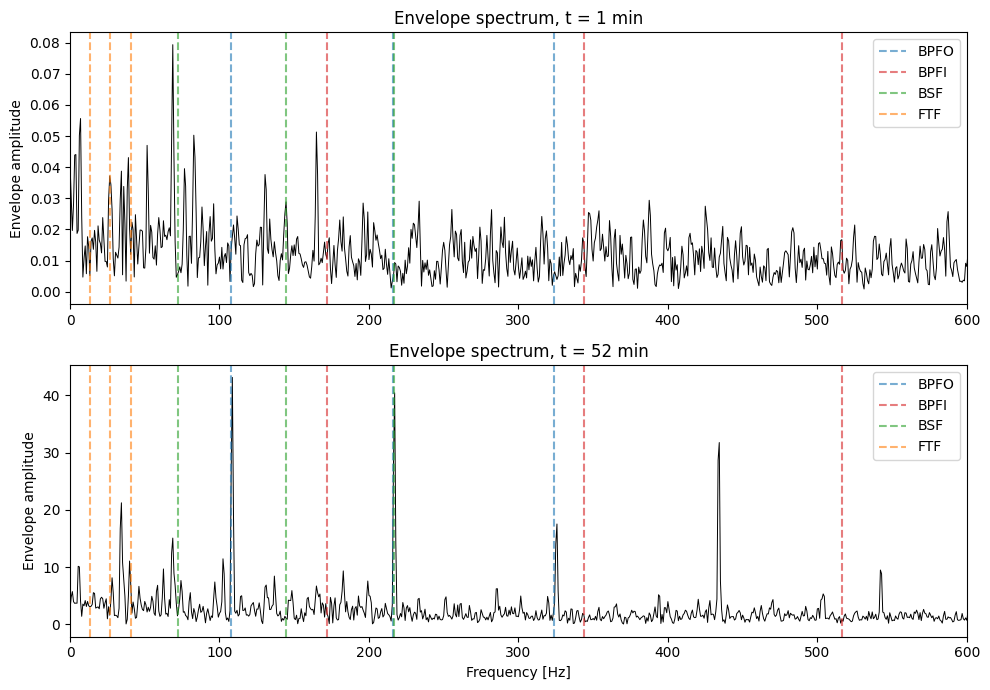

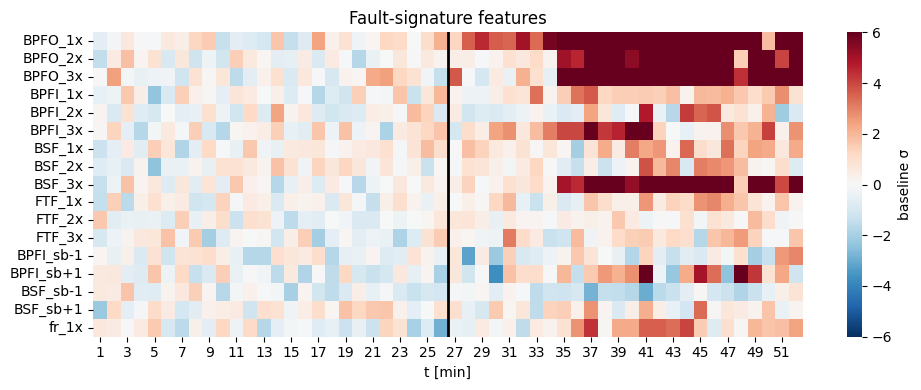

In [32]:
def peak_ratio(f, E, fc, tol=0.03, floor_win=0.2):
    '''Peak within ±tol of fc relative to the local median (noise floor) of the envelope spectrum.'''
    win = (f > fc * (1 - tol)) & (f < fc * (1 + tol))
    ref = (f > fc * (1 - floor_win)) & (f < fc * (1 + floor_win))
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def fault_signature(x, band, fr=fr, n_harm=3):
    f, E = envelope_spectrum(x, band)
    feats = {}
    for name, o in ORDERS.items():
        for h in range(1, n_harm + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio(f, E, h * o * fr))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio(f, E, ORDERS['BPFI'] * fr + s * fr))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio(f, E, 2 * ORDERS['BSF'] * fr + s * ORDERS['FTF'] * fr))
    feats['fr_1x'] = np.log10(peak_ratio(f, E, fr))
    return feats

SIG = pd.DataFrame([fault_signature(x, band) for x in X], index=t)

# z-score relative to the healthy baseline: "how many baseline sigmas above normal"
mu0, sd0 = SIG.iloc[:n_base].mean(), SIG.iloc[:n_base].std() + 1e-6
Z = (SIG - mu0) / sd0

# fault index per type: mean z-score of its harmonics (and sidebands)
FI = pd.DataFrame({k: Z[[c for c in Z.columns if c.startswith(k)]].mean(axis=1) for k in ORDERS}, index=t)

cols = dict(BPFO='tab:blue', BPFI='tab:red', BSF='tab:green', FTF='tab:orange')
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
for a, k in zip(ax, [0, len(X) - 1]):
    f, E = envelope_spectrum(X[k], band)
    a.plot(f, E, 'k', lw=.7); a.set_xlim(0, 600)
    for name, o in ORDERS.items():
        for h in range(1, 4):
            a.axvline(h * o * fr, c=cols[name], ls='--', alpha=.6, label=name if h == 1 else None)
    a.set_ylabel('Envelope amplitude'); a.set_title(f'Envelope spectrum, t = {t[k]} min'); a.legend()
ax[1].set_xlabel('Frequency [Hz]')
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(Z.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
ax.axvline(fpt, c='k', lw=2); ax.set_xlabel('t [min]'); ax.set_title('Fault-signature features')
fig.tight_layout(); plt.show()

## 6. Fault-type clustering (layer 2, gated by the FPT)

Only records with t ≥ FPT are clustered, in the 4-D fault-index space:
- **TEDA / AutoCloud** (online, eccentricity-based, as in your framework): a new cloud opens when a record is atypical (m-σ criterion) for every existing cloud.
- **GMM + BIC** (offline reference).
- **Rule-based label**: dominant fault index if it exceeds 3 baseline σ.

BIC: {1: np.float64(380.9), 2: np.float64(340.6), 3: np.float64(352.3), 4: np.float64(322.0)} -> k = 4
healthy         26
BPFO            18
undetermined     8
Name: count, dtype: int64


,BPFO,BPFI,BSF,FTF,records,minutes,dominant
cloud,,,,,,,
0,1.66,0.20,0.32,0.32,8,27-34,BPFO
1,10.31,1.49,1.92,0.77,17,35-52,BPFO
2,4.39,2.81,0.67,1.41,1,48-48,BPFO


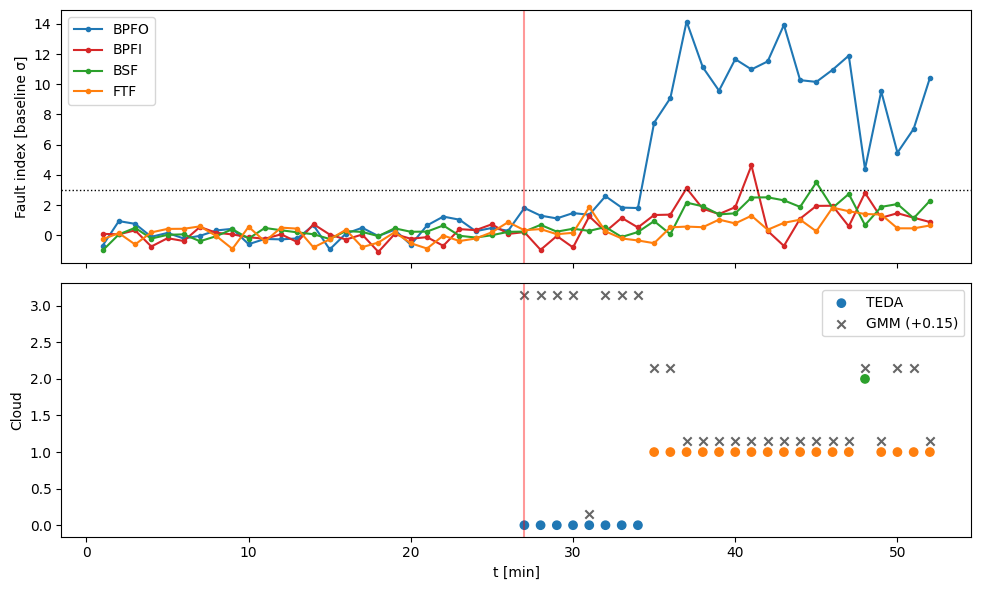

In [33]:
class TEDACloud:
    def __init__(self, x):
        self.n, self.mu, self.var = 1, x.copy(), 0.0

    def ecc(self, x):
        '''Eccentricity of x with respect to the cloud updated with x (recursive TEDA).'''
        n, mu = self.n + 1, (self.n * self.mu + x) / (self.n + 1)
        var = (self.n * self.var + np.sum((x - mu)**2) * n / self.n) / n
        return 1 / n + (np.sum((mu - x)**2) / (n * var) if var > 0 else 0.0), n, mu, var

    def update(self, x):
        _, self.n, self.mu, self.var = self.ecc(x)

class AutoCloudTEDA:
    '''Simplified AutoCloud (Bezerra et al., 2016): eccentricity-based typicality, m-sigma criterion.'''
    def __init__(self, m=3.0):
        self.m, self.clouds, self.labels = m, [], []

    def step(self, x):
        if not self.clouds:
            self.clouds.append(TEDACloud(x)); self.labels.append(0); return 0
        best, best_z = None, np.inf
        for i, c in enumerate(self.clouds):
            xi, n, _, _ = c.ecc(x)
            z = xi / 2
            if n <= 3 or z <= (self.m**2 + 1) / (2 * n):
                c.update(x)
                if z < best_z: best, best_z = i, z
        if best is None:
            self.clouds.append(TEDACloud(x)); best = len(self.clouds) - 1
        self.labels.append(best)
        return best

    def fit(self, Xs):
        for x in Xs: self.step(x)
        return np.array(self.labels)

# layer 2 is gated by the stage layer: only degraded records (t >= FPT) are clustered by fault type
deg = np.arange(len(t)) >= fpt
FId = FI[deg]

ac = AutoCloudTEDA(m=2.0)
lab_teda = ac.fit(FId.values)

# offline reference: GMM with BIC on the same 4-D fault indices
bic = {k: GaussianMixture(k, covariance_type='diag', random_state=0, n_init=10).fit(FId).bic(FId) for k in range(1, 5)}
k_best = min(bic, key=bic.get)
lab_gmm = GaussianMixture(k_best, covariance_type='diag', random_state=0, n_init=10).fit_predict(FId)
print('BIC:', {k: round(v, 1) for k, v in bic.items()}, '-> k =', k_best)

# rule-based label: dominant fault index, if it exceeds 3 baseline sigmas
def dominant_fault(row, thr=3.0):
    return row.idxmax() if row.max() > thr else 'undetermined'
FAULT = FI.apply(dominant_fault, axis=1).where(deg, 'healthy')
print(FAULT.value_counts())

profile = FId.assign(cloud=lab_teda).groupby('cloud').mean().round(2)
profile['records'] = pd.Series(lab_teda).value_counts().sort_index().values
profile['minutes'] = [f'{t[deg][lab_teda == c].min()}-{t[deg][lab_teda == c].max()}' for c in profile.index]
profile['dominant'] = profile[list(ORDERS)].idxmax(axis=1)
display(profile)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for k in ORDERS: ax[0].plot(t, FI[k], '.-', c=cols[k], label=k)
ax[0].axhline(3, c='k', ls=':', lw=1)
ax[0].set_ylabel('Fault index [baseline σ]'); ax[0].legend()
ax[1].scatter(t[deg], lab_teda, c=lab_teda, cmap='tab10', vmin=0, vmax=9, label='TEDA')
ax[1].scatter(t[deg], lab_gmm + 0.15, marker='x', c='0.4', label='GMM (+0.15)')
ax[1].set_ylabel('Cloud'); ax[1].set_xlabel('t [min]'); ax[1].legend()
for a in ax: a.axvline(t[fpt], c='r', alpha=.4)
fig.tight_layout(); plt.show()

## 7. Notes on interpretation

- **Single bearing:** a single run-to-failure trajectory has one failure mode, so the clouds found here separate *severity phases of the same fault* (incipient vs. developed outer-race damage), not different fault types. Fault-type clustering needs the signatures of several bearings (Bearing1_1 ... 3_5) in the same feature space; since the fault indices are expressed in orders of `fr` and in baseline-σ units, records from the three operating conditions can be stacked directly (set `fr` per condition: 35, 37.5, 40 Hz).
- **Ground truth:** the XJTU-SY fault labels describe the post-mortem state only; evaluate cluster purity / ARI on the late-life records.
- **Band:** the kurtogram criterion is evaluated only on degraded records (t ≥ FPT), so it uses information up to the FPT; online, it can be re-evaluated as new degraded records arrive.
- **Thresholds:** `n_base`, the 3σ / 3-consecutive FPT rule, `m` of TEDA and the 3σ dominance threshold are the tunable parameters.